# Mathematical Modeling and Design of a Reinforced Concrete Beam according to Eurocode 2

**SoftUni – Math Concepts for Developers**
**Date:** October 2026

## 1. Introduction and Problem Statement

This project presents a complete workflow for the design of a simply supported reinforced concrete beam according to Eurocode 2 (EN 1992-1-1).

The main goals are:
- To demonstrate the relationship between statics and calculus (derivatives of internal forces)
- To implement the flexural and shear design procedures of EC2 in clean, readable Python
- To validate the results against an existing Mathcad calculation
- To perform parametric studies and visualize the behavior of the beam

The project follows the scientific approach: problem formulation → mathematical model → implementation → validation → analysis.

## 2. Input Data

We start with the geometry, material properties and loading of the beam.

In [1]:
# Geometry
b = 300          # mm - beam width
h = 450          # mm - beam height
l = 6000         # mm - span length
cnom = 35        # mm - concrete cover
link = 8         # mm - diameter of links
phi = 20         # mm - tension reinforcement diameter
phi_comp = 14    # mm - compression reinforcement diameter
dg = 20          # mm - maximum aggregate size

# Materials
fck = 30         # MPa - concrete C30/37
fyk = 500        # MPa - characteristic yield strength of reinforcement
fywk = 500       # MPa - characteristic yield strength of shear reinforcement
gamma_c = 1.5    # partial factor for concrete
gamma_s = 1.15   # partial factor for steel

# Design strengths
fyd = fyk / gamma_s
fywd = fywk / gamma_s

# Loading
gk = 20        # kN/m - permanent load (SLS)
qk = 10        # kN/m - variable load (SLS)

# Other
delta = 0.85     # redistribution ratio

print("Input data loaded successfully.")
print(f"Effective span l = {l} mm")
print(f"Design yield strength fyd = {fyd:.1f} MPa")

Input data loaded successfully.
Effective span l = 6000 mm
Design yield strength fyd = 434.8 MPa


## 3. Static Analysis and Differential Relationships

For a simply supported beam with uniformly distributed load \( q \), the internal forces are related through the following differential equations:

$$
\frac{dV}{dx} = -q(x)
$$

$$
\frac{dM}{dx} = V(x)
$$

These relationships come directly from equilibrium of an infinitesimal beam element.

**Important consequence:**
The bending moment \( M \) reaches an extremum (usually maximum) where the shear force \( V = 0 \).

We will:
1. Derive the analytical expressions for \( V(x) \) and \( M(x) \)
2. Find the location and value of \( M_{\max} \) by setting \( V(x) = 0 \)
3. Verify the derivative relationship numerically

### 3.1 Analytical solution

Total design load:
$$ q = 1.35 g_k + 1.5 q_k $$

Shear force:
$$ V(x) = \frac{q l}{2} - q x $$

Bending moment:
$$ M(x) = \frac{q l}{2} x - \frac{q x^2}{2} $$

Maximum moment occurs at midspan (\( x = l/2 \)):
$$ M_{\max} = \frac{q l^2}{8} $$

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Design load (kN/m) (ULS)
q = 1.35 * gk + 1.5 * qk
print(f"Design load q = {q:.2f} kN/m")

# Convert span to meters for convenience in diagrams
L = l / 1000  # m

# Analytical functions
def V(x):
    """Shear force in kN, x in meters"""
    return (q * L / 2) - q * x

def M(x):
    """Bending moment in kNm, x in meters"""
    return (q * L / 2) * x - (q * x**2) / 2

# Location of maximum moment (where V = 0)
x_max = L / 2
M_Ed = M(x_max)

print(f"\nMaximum moment occurs at x = {x_max:.2f} m")
print(f"M_Ed = {M_Ed:.1f} kNm")


Design load q = 42.00 kN/m

Maximum moment occurs at x = 3.00 m
M_Ed = 189.0 kNm


### 3.2 Numerical verification of the derivative relationship

We check that the numerical derivative of \( M(x) \) is approximately equal to \( V(x) \).

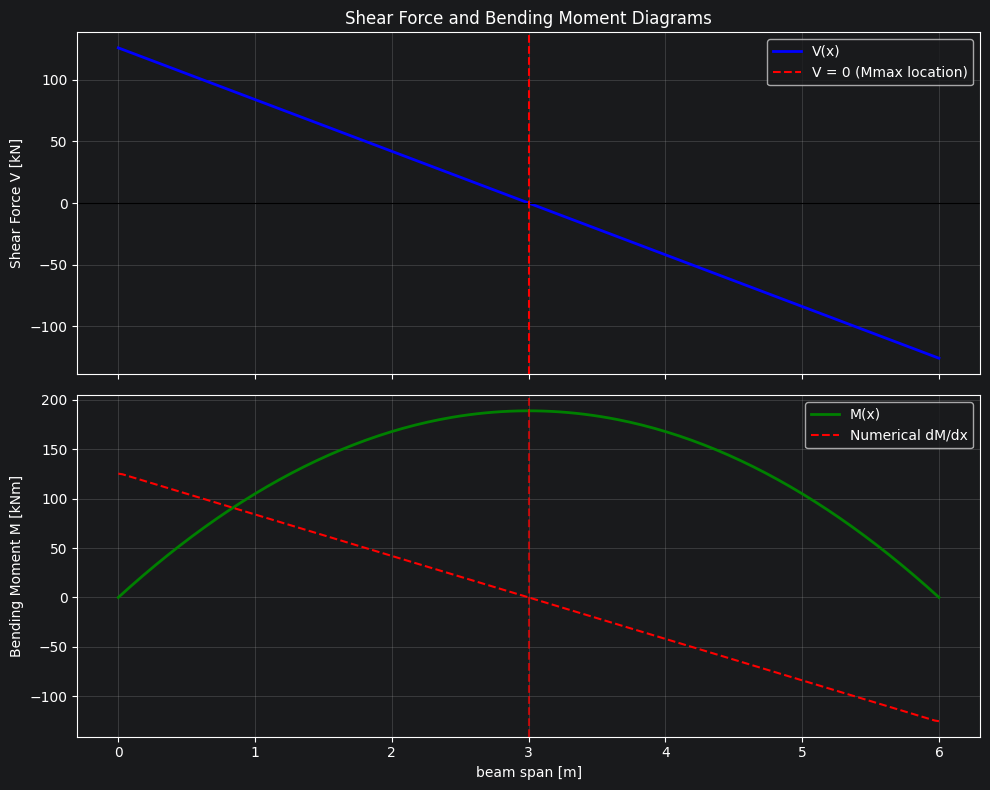

Max absolute difference between V(x) and dM/dx: 0.633166 kN


In [3]:
# Create points along the beam
x = np.linspace(0, L, 200)
V_values = V(x)
M_values = M(x)

# Numerical derivative of M
dM_dx = np.gradient(M_values, x)

# Plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Shear diagram
ax1.plot(x, V_values, 'b-', linewidth=2, label='V(x)')
ax1.axhline(0, color='k', linewidth=0.8)
ax1.axvline(x_max, color='r', linestyle='--', label='V = 0 (Mmax location)')
ax1.set_ylabel('Shear Force V [kN]')
ax1.set_title('Shear Force and Bending Moment Diagrams')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Moment diagram
ax2.plot(x, M_values, 'g-', linewidth=2, label='M(x)')
ax2.plot(x, dM_dx, 'r--', linewidth=1.5, label='Numerical dM/dx')
ax2.axvline(x_max, color='r', linestyle='--', alpha=0.7)
ax2.set_xlabel('Beam span [m]')
ax2.set_ylabel('Bending Moment M [kNm]')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Check how close the derivative is
print(f"Max absolute difference between V(x) and dM/dx: {np.max(np.abs(V_values - dM_dx)):.6f} kN")

## 4. Flexural Design

We now design the beam for the maximum bending moment obtained from the static analysis.

### 4.1 Effective depth

The effective depth \( d \) is calculated as:

$$
d = h - c_{nom} - \phi_{link} - \frac{\phi}{2}
$$

In [4]:
# Effective depth
d = h - cnom - link - phi / 2
d2 = cnom + link + phi_comp / 2   # distance to compression reinforcement

print(f"Effective depth d = {d:.0f} mm")
print(f"d2 = {d2:.0f} mm")

Effective depth d = 397 mm
d2 = 50 mm


### 4.2 Parameters K and K'

$$
K = \frac{M_{Ed}}{b d^2 f_{ck}}
$$

$$
K' = 0.6\delta - 0.18\delta^2 - 0.21
$$

If \( K \leq K' \), no compression reinforcement is required.

In [5]:
# Use the analytically calculated M_max (convert to kNm is already done)
M_Ed_calc = M_Ed   # kNm from previous section

# K factor (note: units consistency - M in Nmm, b and d in mm, fck in MPa)
M_Ed_Nmm = M_Ed_calc * 1e6          # convert kNm to Nmm
K = M_Ed_Nmm / (b * d**2 * fck)

K_prime = 0.6 * delta - 0.18 * delta**2 - 0.21

print(f"K = {K:.4f}")
print(f"K' = {K_prime:.4f}")

if K <= K_prime:
    print("→ No compression reinforcement required (K ≤ K')")
else:
    print("→ Compression reinforcement is required")

K = 0.1332
K' = 0.1700
→ No compression reinforcement required (K ≤ K')


### 4.3 Lever arm z and required reinforcement

The lever arm \( z \) is limited to \( 0.95d \).

Required tension reinforcement:
$$
A_{s,req} = \frac{M_{Ed}}{f_{yd} \cdot z}
$$

In [6]:
# Lever arm z
if K <= K_prime:
    z = min(d/2 * (1 + np.sqrt(1 - 3.53*K)), 0.95*d)
else:
    z = d/2 * (1 + np.sqrt(1 - 3.53*K_prime))

print(f"Lever arm z = {z:.0f} mm")

# Required tension reinforcement
As_req = (M_Ed_Nmm) / (fyd * z)   # mm²

print(f"Required tension reinforcement As,req = {As_req:.0f} mm²")

Lever arm z = 343 mm
Required tension reinforcement As,req = 1267 mm²


In [7]:
# Provided reinforcement: 5∅20
n_bars = 5
As_prov = n_bars * np.pi * (phi**2) / 4

print(f"Provided As = {As_prov:.0f} mm² ({n_bars}∅{phi})")

# Bending capacity
M_Rd = As_prov * z * fyd / 1e6   # kNm
print(f"M_Rd = {M_Rd:.1f} kNm")
print(f"M_Ed = {M_Ed_calc:.1f} kNm")

if M_Rd >= M_Ed_calc:
    print("→ Therefore satisfactory")
else:
    print("→ Bending capacity is insufficient")

Provided As = 1571 mm² (5∅20)
M_Rd = 234.2 kNm
M_Ed = 189.0 kNm
→ Therefore satisfactory


### 4.4 Minimum and maximum reinforcement

According to EC2:

$$
A_{s,\min} = \max\left(0.26\frac{f_{ctm}}{f_{yk}}b d,\ 0.0013 b d\right)
$$

$$
A_{s,\max} = 0.04\, b\, h
$$

In [8]:
# Mean tensile strength of concrete
fctm = 0.3 * fck**(2/3)

As_min = max(0.26 * (fctm / fyk) * b * d, 0.0013 * b * d)
As_max = 0.04 * b * h

print(f"fctm = {fctm:.2f} MPa")
print(f"As,min = {As_min:.0f} mm²")
print(f"As,max = {As_max:.0f} mm²")
print(f"As,prov = {As_prov:.0f} mm²")

if As_min <= As_prov <= As_max:
    print("→ Provided reinforcement is within limits")
else:
    print("→ Provided reinforcement is outside the allowed limits")

fctm = 2.90 MPa
As,min = 179 mm²
As,max = 5400 mm²
As,prov = 1571 mm²
→ Provided reinforcement is within limits


### 4.5 Bar spacing check

Clear spacing between bars must satisfy:

$$
a \geq \max(20\ \text{mm},\ \phi,\ d_g + 5\ \text{mm})
$$

In [10]:
# Clear spacing
n_bars = 5          # актуално: 5∅20
spacing = (b - 2*cnom - 2*link - n_bars*phi) / (n_bars - 1)

a_min = max(20, phi, dg + 5)

print(f"Clear spacing between bars = {spacing:.1f} mm")
print(f"Minimum required clear spacing = {a_min:.1f} mm")

if spacing >= a_min:
    print("→ Spacing is OK")
else:
    print("→ Spacing is insufficient")

Clear spacing between bars = 28.5 mm
Minimum required clear spacing = 25.0 mm
→ Spacing is OK
